In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2, ResNet50, EfficientNetB0
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (EarlyStopping, ModelCheckpoint,
                                        ReduceLROnPlateau)
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from types import SimpleNamespace
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi']        = 120
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

RIPENESS_PATH = '/content/drive/MyDrive/banana_project_napinas/ripeness_dataset'
TRAIN_DIR     = os.path.join(RIPENESS_PATH, 'train')
VAL_DIR       = os.path.join(RIPENESS_PATH, 'val')
TEST_DIR      = os.path.join(RIPENESS_PATH, 'test')
SAVE_DIR      = '/content/drive/MyDrive/banana_project_napinas/ripeness_results'
MODEL_DIR     = '/content/drive/MyDrive/banana_project_napinas'
os.makedirs(SAVE_DIR, exist_ok=True)

IMG_SIZE     = (224, 224)
BATCH_SIZE   = 32
NUM_CLASSES  = 4
CLASS_NAMES  = ['unripe', 'ripe', 'overripe', 'rotten']
CLASS_COLORS = ['#27ae60', '#f1c40f', '#e67e22', '#c0392b']

MODEL_CONFIGS = {
    'MobileNetV2': {
        'lr_p1':     1e-3,
        'lr_p2':     1e-5,
        'epochs_p1': 15,
        'epochs_p2': 30,
        'unfreeze':  30,
        'rescale':   True,
    },
    'ResNet50': {
        'lr_p1':     1e-3,
        'lr_p2':     1e-5,
        'epochs_p1': 15,
        'epochs_p2': 30,
        'unfreeze':  30,
        'rescale':   True,
    },
    'EfficientNetB0': {
        'lr_p1':     1e-3,
        'lr_p2':     1e-5,
        'epochs_p1': 15,
        'epochs_p2': 30,
        'unfreeze':  30,
        'rescale':   False,
    },
}

print(f"✅ TensorFlow {tf.__version__}")
print(f"✅ GPU: {tf.config.list_physical_devices('GPU')}")
print(f"✅ Classes: {CLASS_NAMES}")
print(f"✅ Models to train: {list(MODEL_CONFIGS.keys())}")

✅ TensorFlow 2.20.0
✅ GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ Classes: ['unripe', 'ripe', 'overripe', 'rotten']
✅ Models to train: ['MobileNetV2', 'ResNet50', 'EfficientNetB0']


In [3]:
def make_generators(rescale=True):
    scale = 1./255 if rescale else 1.0

    train_datagen = ImageDataGenerator(
        rescale=scale,
        rotation_range=25,
        width_shift_range=0.15,
        height_shift_range=0.15,
        horizontal_flip=True,
        brightness_range=[0.75, 1.25],
        zoom_range=0.2,
        shear_range=0.1,
        fill_mode='nearest'
    )
    val_datagen = ImageDataGenerator(rescale=scale)

    train_gen = train_datagen.flow_from_directory(
        TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='categorical', shuffle=True, classes=CLASS_NAMES
    )
    val_gen = val_datagen.flow_from_directory(
        VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='categorical', shuffle=False, classes=CLASS_NAMES
    )
    test_gen = val_datagen.flow_from_directory(
        TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='categorical', shuffle=False, classes=CLASS_NAMES
    )
    return train_gen, val_gen, test_gen

# Compute class weights once
base_gen, _, _ = make_generators(rescale=True)
class_weights  = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=base_gen.classes
)
class_weight_dict = dict(enumerate(class_weights))

print("⚖️  Class weights:")
for i, cls in enumerate(CLASS_NAMES):
    print(f"   {cls}: {class_weight_dict[i]:.4f}")
print(f"\n✅ Train: {base_gen.samples} images")

Found 2096 images belonging to 4 classes.
Found 700 images belonging to 4 classes.
Found 699 images belonging to 4 classes.
⚖️  Class weights:
   unripe: 0.6114
   ripe: 1.0716
   overripe: 1.5642
   rotten: 1.2627

✅ Train: 2096 images


In [4]:
def build_model(backbone_name):
    cfg = MODEL_CONFIGS[backbone_name]

    if backbone_name == 'MobileNetV2':
        base = MobileNetV2(input_shape=(224,224,3),
                           include_top=False, weights='imagenet')
    elif backbone_name == 'ResNet50':
        base = ResNet50(input_shape=(224,224,3),
                        include_top=False, weights='imagenet')
    elif backbone_name == 'EfficientNetB0':
        base = EfficientNetB0(input_shape=(224,224,3),
                              include_top=False, weights='imagenet')

    base.trainable = False

    inputs  = tf.keras.Input(shape=(224, 224, 3))
    x       = base(inputs, training=False)
    x       = layers.GlobalAveragePooling2D()(x)
    x       = layers.BatchNormalization()(x)
    x       = layers.Dense(256, activation='relu')(x)
    x       = layers.Dropout(0.4)(x)
    x       = layers.Dense(128, activation='relu')(x)
    x       = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=cfg['lr_p1']),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model, base

print("✅ Model builder ready!")

✅ Model builder ready!


In [5]:
def _save_result_to_json(backbone_name, result):
    results_json_path = f'{SAVE_DIR}/ripeness_training_results.json'
    existing = {}
    if os.path.exists(results_json_path):
        with open(results_json_path, 'r') as f:
            existing = json.load(f)

    h1 = result['history1']
    h2 = result['history2']
    existing[backbone_name] = {
        'name':         backbone_name,
        'loss':         float(result['loss']),
        'accuracy':     float(result['accuracy']),
        'y_true':       result['y_true'].tolist()
                        if hasattr(result['y_true'], 'tolist')
                        else result['y_true'],
        'y_pred':       result['y_pred'].tolist()
                        if hasattr(result['y_pred'], 'tolist')
                        else result['y_pred'],
        'y_pred_probs': result['y_pred_probs'].tolist()
                        if hasattr(result['y_pred_probs'], 'tolist')
                        else result['y_pred_probs'],
        'report':       result['report'],
        'history1':     h1.history if hasattr(h1, 'history') else h1,
        'history2':     h2.history if hasattr(h2, 'history') else h2,
    }
    with open(results_json_path, 'w') as f:
        json.dump(existing, f)


def train_model(backbone_name):
    cfg = MODEL_CONFIGS[backbone_name]
    results_json_path = f'{SAVE_DIR}/ripeness_training_results.json'

    # ── Skip if already trained ────────────────────────────────────────
    if os.path.exists(results_json_path):
        with open(results_json_path, 'r') as f:
            existing = json.load(f)
        if backbone_name in existing:
            print(f"⏭️  {backbone_name} already trained — loading from save!")
            r = existing[backbone_name]
            best_path  = f'{MODEL_DIR}/ripeness_{backbone_name}_best.keras'
            final_path = f'{MODEL_DIR}/ripeness_{backbone_name}_final.keras'
            model_path = best_path  if os.path.exists(best_path)  else \
                         final_path if os.path.exists(final_path) else None
            model = tf.keras.models.load_model(model_path) if model_path else None
            return {
                'name':         backbone_name,
                'model':        model,
                'loss':         float(r['loss']),
                'accuracy':     float(r['accuracy']),
                'y_true':       np.array(r['y_true']),
                'y_pred':       np.array(r['y_pred']),
                'y_pred_probs': np.array(r['y_pred_probs']),
                'report':       r['report'],
                'history1':     SimpleNamespace(history=r['history1'])
                                if r.get('history1') else None,
                'history2':     SimpleNamespace(history=r['history2'])
                                if r.get('history2') else None,
            }

    print(f"\n{'='*55}")
    print(f"  🚀 Training: {backbone_name}")
    print(f"  LR P1: {cfg['lr_p1']} | LR P2: {cfg['lr_p2']}")
    print(f"  Epochs P1: {cfg['epochs_p1']} | P2: {cfg['epochs_p2']}")
    print(f"{'='*55}")

    train_gen, val_gen, test_gen = make_generators(rescale=cfg['rescale'])
    model, base = build_model(backbone_name)

    # ── Phase 1 ────────────────────────────────────────────────────────
    print("\n📍 Phase 1: Training head only (base frozen)...")
    cb_p1 = [
        EarlyStopping(patience=6, restore_best_weights=True,
                      monitor='val_accuracy', verbose=1),
        ModelCheckpoint(
            f'{MODEL_DIR}/ripeness_{backbone_name}_p1.keras',
            save_best_only=True, monitor='val_accuracy', verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=3, min_lr=1e-7, verbose=1)
    ]
    h1 = model.fit(
        train_gen, epochs=cfg['epochs_p1'],
        validation_data=val_gen,
        class_weight=class_weight_dict,
        callbacks=cb_p1, verbose=1
    )
    print(f"   ✅ Phase 1 best: {max(h1.history['val_accuracy'])*100:.2f}%")

    # ── Phase 2 ────────────────────────────────────────────────────────
    base.trainable = True
    for layer in base.layers[:-cfg['unfreeze']]:
        layer.trainable = False
    model.compile(
        optimizer=optimizers.Adam(learning_rate=cfg['lr_p2']),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    print(f"\n📍 Phase 2: Fine-tuning top {cfg['unfreeze']} layers...")
    cb_p2 = [
        EarlyStopping(patience=8, restore_best_weights=True,
                      monitor='val_accuracy', verbose=1),
        ModelCheckpoint(
            f'{MODEL_DIR}/ripeness_{backbone_name}_best.keras',
            save_best_only=True, monitor='val_accuracy', verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.3,
                          patience=4, min_lr=1e-8, verbose=1)
    ]
    h2 = model.fit(
        train_gen, epochs=cfg['epochs_p2'],
        validation_data=val_gen,
        class_weight=class_weight_dict,
        callbacks=cb_p2, verbose=1
    )
    print(f"   ✅ Phase 2 best: {max(h2.history['val_accuracy'])*100:.2f}%")

    # ── Evaluate ───────────────────────────────────────────────────────
    test_gen.reset()
    loss, acc    = model.evaluate(test_gen, verbose=0)
    y_pred_probs = model.predict(test_gen, verbose=0)
    y_pred       = np.argmax(y_pred_probs, axis=1)
    y_true       = test_gen.classes
    report       = classification_report(
                       y_true, y_pred,
                       target_names=CLASS_NAMES,
                       output_dict=True
                   )
    print(f"\n   🎯 Test Accuracy: {acc*100:.2f}%")
    print(f"   📉 Test Loss:     {loss:.4f}")

    # ── Save final model & JSON ────────────────────────────────────────
    model.save(f'{MODEL_DIR}/ripeness_{backbone_name}_final.keras')

    result = {
        'name':         backbone_name,
        'model':        model,
        'loss':         loss,
        'accuracy':     acc,
        'y_true':       y_true,
        'y_pred':       y_pred,
        'y_pred_probs': y_pred_probs,
        'report':       report,
        'history1':     h1,
        'history2':     h2,
    }
    _save_result_to_json(backbone_name, result)
    print(f"   💾 {backbone_name} saved to JSON & Drive!")
    return result

print("✅ Training functions ready!")
print("💡 Already trained models are skipped automatically!")

✅ Training functions ready!
💡 Already trained models are skipped automatically!


In [6]:
results = {}

for backbone in ['MobileNetV2', 'ResNet50', 'EfficientNetB0']:
    results[backbone] = train_model(backbone)

print("\n" + "="*55)
print("      RIPENESS TRAINING COMPLETE — SUMMARY")
print("="*55)
print(f"{'Model':<18} {'Accuracy':>10} {'F1 Macro':>10} {'Loss':>8}")
print("-"*55)
for name, r in results.items():
    f1 = r['report']['macro avg']['f1-score']
    print(f"{name:<18} {r['accuracy']*100:>9.2f}%"
          f" {f1:>10.3f} {r['loss']:>8.4f}")
print("="*55)


  🚀 Training: MobileNetV2
  LR P1: 0.001 | LR P2: 1e-05
  Epochs P1: 15 | P2: 30
Found 2096 images belonging to 4 classes.
Found 700 images belonging to 4 classes.
Found 699 images belonging to 4 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

📍 Phase 1: Training head only (base frozen)...
Epoch 1/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 824s 12s/step - accuracy: 0.6403 - loss: 0.9579 - val_accuracy: 0.8386 - val_loss: 0.4811 - learning_rate: 0.0010
Epoch 2/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 45s 677ms/step - accuracy: 0.7667 - loss: 0.6194 - val_accuracy: 0.8543 - val_loss: 0.3807 - learning_rate: 0.0010
Epoch 3/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 44s 673ms/step - accuracy: 0.8063 - loss: 0.5153 - val_accuracy: 0.8600 - val_loss: 0.3924 - learning_rate: 0.0010
Epoch 4/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 44s 663ms/step - accuracy: 0.8220 - loss: 0.4634 - val_accuracy: 0.8571 - val_loss: 0.3579 - learning_rate: 0.0010
Epoch 5/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 45s 676ms/step - accuracy: 0.8240 - loss: 0.4564

In [6]:
# ── RUN THIS INSTEAD OF CELL 6 IF COLAB DISCONNECTS ──────────────────
import os, json, numpy as np, tensorflow as tf
from types import SimpleNamespace

results_json_path = f'{SAVE_DIR}/ripeness_training_results.json'

if not os.path.exists(results_json_path):
    print("❌ No saved results — run Cell 6 to train first!")
else:
    with open(results_json_path, 'r') as f:
        saved = json.load(f)

    results = {}
    for name, r in saved.items():
        print(f"🔄 Restoring {name}...")
        best_path  = f'{MODEL_DIR}/ripeness_{name}_best.keras'
        final_path = f'{MODEL_DIR}/ripeness_{name}_final.keras'
        model_path = best_path  if os.path.exists(best_path)  else \
                     final_path if os.path.exists(final_path) else None
        model = tf.keras.models.load_model(model_path) if model_path else None

        results[name] = {
            'name':         r['name'],
            'model':        model,
            'loss':         float(r['loss']),
            'accuracy':     float(r['accuracy']),
            'y_true':       np.array(r['y_true']),
            'y_pred':       np.array(r['y_pred']),
            'y_pred_probs': np.array(r['y_pred_probs']),
            'report':       r['report'],
            'history1':     SimpleNamespace(history=r['history1'])
                            if r.get('history1') else None,
            'history2':     SimpleNamespace(history=r['history2'])
                            if r.get('history2') else None,
        }
        status = "✅ model loaded" if model else "⚠️ model missing"
        print(f"   {name}: {r['accuracy']*100:.2f}% — {status}")

    print(f"\n✅ Recovered: {list(results.keys())}")
    print("▶️  Skip to Cell 8 for visuals!")

🔄 Restoring MobileNetV2...
   MobileNetV2: 88.98% — ✅ model loaded
🔄 Restoring ResNet50...
   ResNet50: 74.96% — ✅ model loaded
🔄 Restoring EfficientNetB0...
   EfficientNetB0: 91.56% — ✅ model loaded

✅ Recovered: ['MobileNetV2', 'ResNet50', 'EfficientNetB0']
▶️  Skip to Cell 8 for visuals!


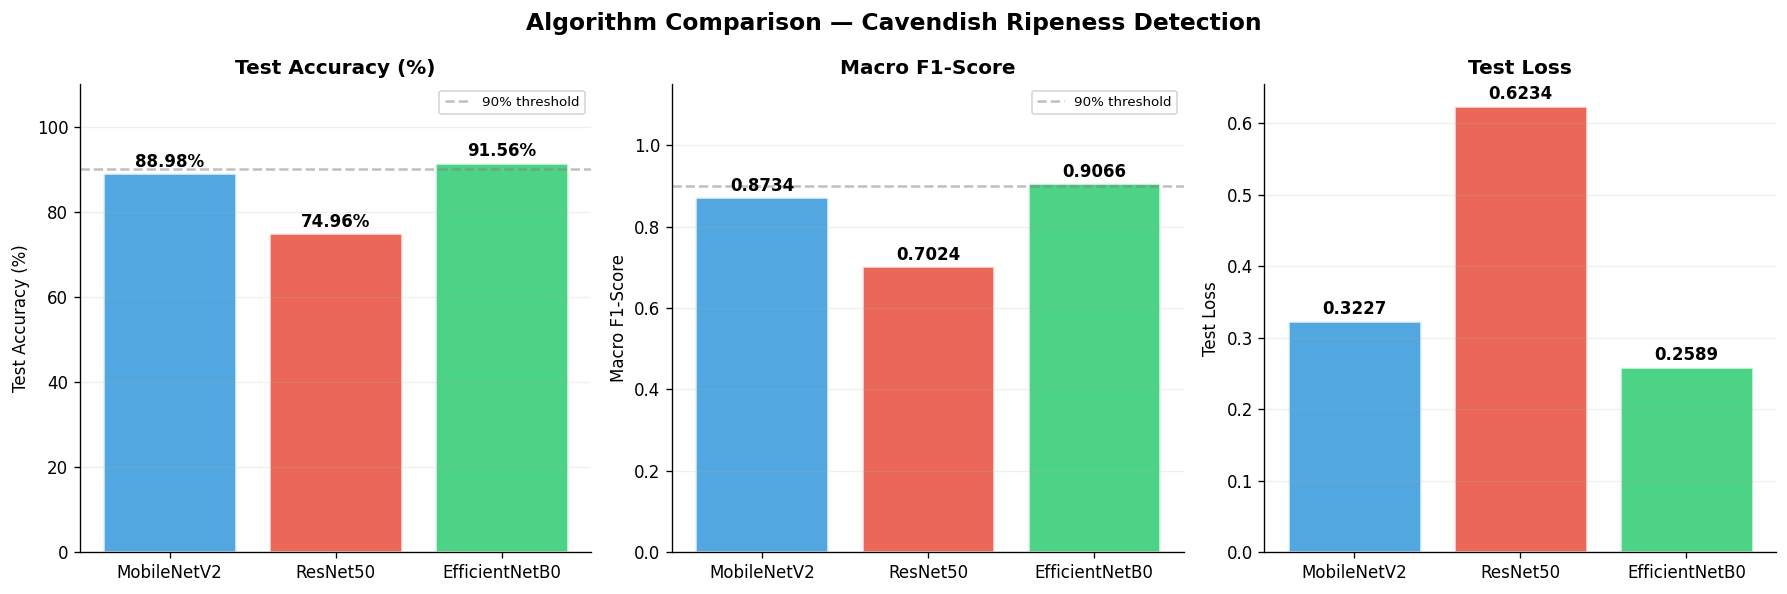

In [7]:
model_names = list(results.keys())
accuracies  = [results[m]['accuracy'] * 100 for m in model_names]
losses      = [results[m]['loss'] for m in model_names]
f1_macros   = [results[m]['report']['macro avg']['f1-score']
               for m in model_names]
colors      = ['#3498db', '#e74c3c', '#2ecc71']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Algorithm Comparison — Cavendish Ripeness Detection',
             fontsize=14, fontweight='bold')

metrics = [
    (axes[0], accuracies, 'Test Accuracy (%)', '%',  0,   110),
    (axes[1], f1_macros,  'Macro F1-Score',    '',   0,   1.15),
    (axes[2], losses,     'Test Loss',          '',   None, None),
]
for ax, vals, title, suffix, ymin, ymax in metrics:
    bars = ax.bar(model_names, vals, color=colors,
                  alpha=0.85, edgecolor='white', linewidth=1.5)
    for bar, val in zip(bars, vals):
        label = f'{val:.2f}{suffix}' if suffix == '%' else f'{val:.4f}'
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + (0.5 if suffix == '%' else 0.005),
                label, ha='center', va='bottom',
                fontweight='bold', fontsize=10)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel(title)
    if ymin is not None:
        ax.set_ylim(ymin, ymax)
    ax.grid(True, alpha=0.2, axis='y')
    if title != 'Test Loss':
        thresh = 90 if suffix == '%' else 0.9
        ax.axhline(y=thresh, color='gray', linestyle='--',
                   alpha=0.5, label='90% threshold')
        ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/01_algorithm_comparison.png', bbox_inches='tight')
plt.show()

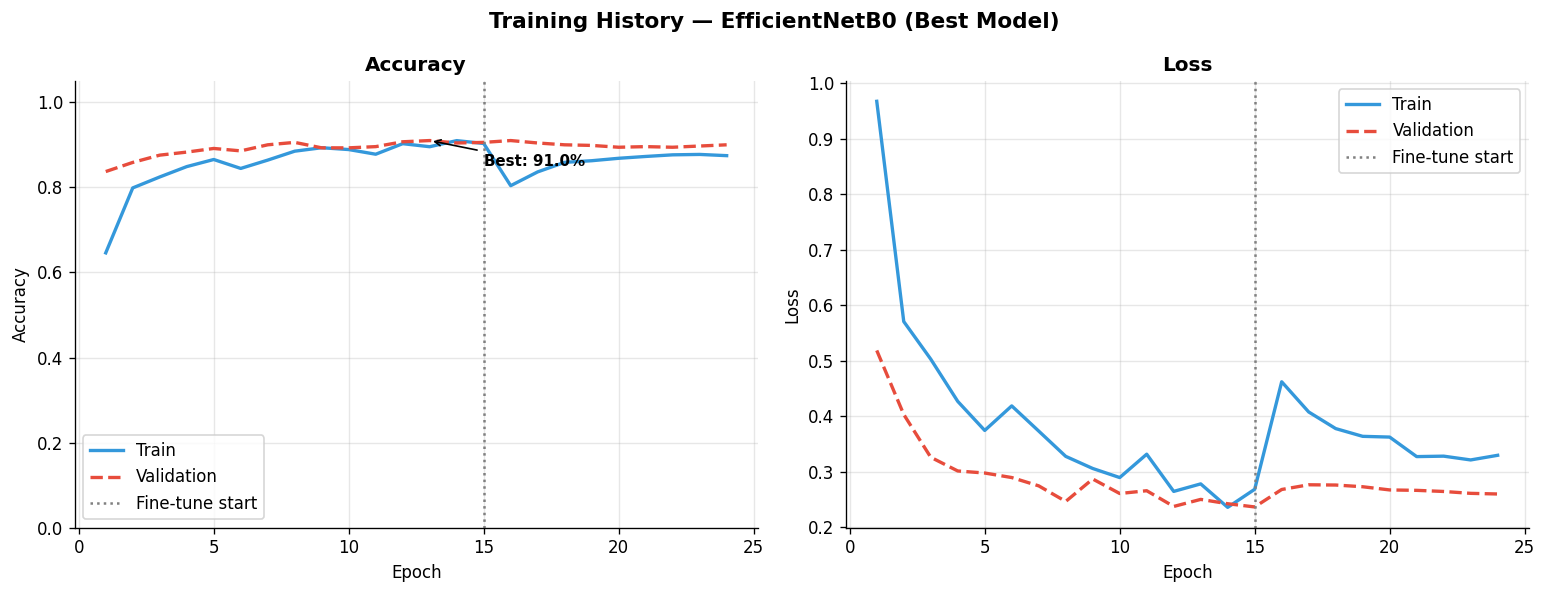

🏆 Best model: EfficientNetB0 — 91.00% val accuracy


In [8]:
best_name = max(results, key=lambda m: results[m]['accuracy'])
best      = results[best_name]
h1, h2    = best['history1'], best['history2']

acc      = h1.history['accuracy']     + h2.history['accuracy']
val_acc  = h1.history['val_accuracy'] + h2.history['val_accuracy']
loss_h   = h1.history['loss']         + h2.history['loss']
val_loss = h1.history['val_loss']     + h2.history['val_loss']
epochs   = range(1, len(acc) + 1)
split    = len(h1.history['accuracy'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(f'Training History — {best_name} (Best Model)',
             fontsize=13, fontweight='bold')

ax1.plot(epochs, acc,     color='#3498db', linewidth=2, label='Train')
ax1.plot(epochs, val_acc, color='#e74c3c', linewidth=2,
         linestyle='--', label='Validation')
ax1.axvline(x=split, color='gray', linestyle=':',
            linewidth=1.5, label='Fine-tune start')
best_val = max(val_acc)
best_ep  = val_acc.index(best_val) + 1
ax1.annotate(f'Best: {best_val*100:.1f}%',
             xy=(best_ep, best_val),
             xytext=(best_ep + 2, best_val - 0.06),
             arrowprops=dict(arrowstyle='->', color='black'),
             fontsize=9, fontweight='bold')
ax1.set_ylim(0, 1.05)
ax1.set_title('Accuracy', fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(epochs, loss_h,   color='#3498db', linewidth=2, label='Train')
ax2.plot(epochs, val_loss, color='#e74c3c', linewidth=2,
         linestyle='--', label='Validation')
ax2.axvline(x=split, color='gray', linestyle=':',
            linewidth=1.5, label='Fine-tune start')
ax2.set_title('Loss', fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/02_training_history.png', bbox_inches='tight')
plt.show()
print(f"🏆 Best model: {best_name} — {best_val*100:.2f}% val accuracy")

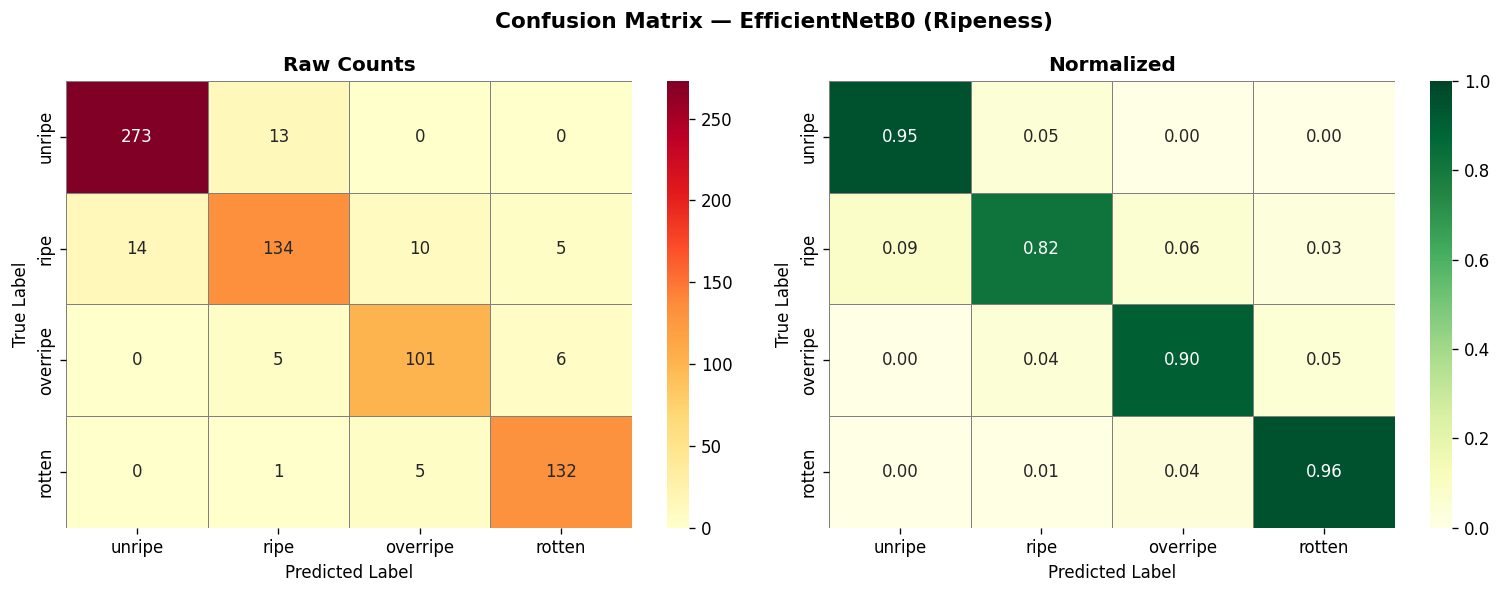

In [9]:
y_true  = best['y_true']
y_pred  = best['y_pred']
cm      = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
labels  = CLASS_NAMES

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(f'Confusion Matrix — {best_name} (Ripeness)',
             fontsize=13, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrRd', ax=axes[0],
            xticklabels=labels, yticklabels=labels,
            linewidths=0.5, linecolor='gray')
axes[0].set_title('Raw Counts', fontweight='bold')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='YlGn', ax=axes[1],
            xticklabels=labels, yticklabels=labels,
            linewidths=0.5, linecolor='gray', vmin=0, vmax=1)
axes[1].set_title('Normalized', fontweight='bold')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/03_confusion_matrix.png', bbox_inches='tight')
plt.show()

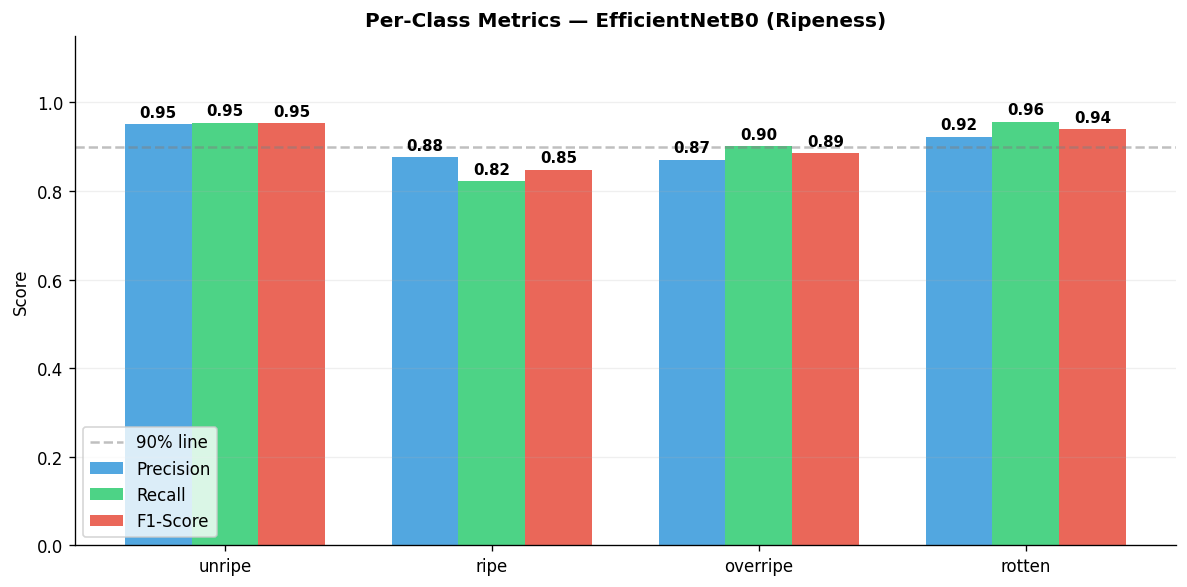


📊 Full Classification Report — EfficientNetB0:
              precision    recall  f1-score   support

      unripe       0.95      0.95      0.95       286
        ripe       0.88      0.82      0.85       163
    overripe       0.87      0.90      0.89       112
      rotten       0.92      0.96      0.94       138

    accuracy                           0.92       699
   macro avg       0.91      0.91      0.91       699
weighted avg       0.92      0.92      0.92       699



In [10]:
report = best['report']
df = pd.DataFrame(report).T.loc[CLASS_NAMES,
                                ['precision','recall','f1-score']]
x, w = np.arange(NUM_CLASSES), 0.25

fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x-w, df['precision'], w, label='Precision',
            color='#3498db', alpha=0.85)
b2 = ax.bar(x,   df['recall'],   w, label='Recall',
            color='#2ecc71', alpha=0.85)
b3 = ax.bar(x+w, df['f1-score'], w, label='F1-Score',
            color='#e74c3c', alpha=0.85)

for bars in [b1, b2, b3]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.01,
                f'{bar.get_height():.2f}',
                ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, fontsize=10)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score')
ax.set_title(f'Per-Class Metrics — {best_name} (Ripeness)',
             fontweight='bold')
ax.axhline(y=0.9, color='gray', linestyle='--',
           alpha=0.5, label='90% line')
ax.legend()
ax.grid(True, alpha=0.2, axis='y')

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/04_per_class_metrics.png', bbox_inches='tight')
plt.show()

print(f"\n📊 Full Classification Report — {best_name}:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

In [11]:
best_model = best['model']

converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
tflite_model = converter.convert()

tflite_path = f'{MODEL_DIR}/ripeness_model.tflite'
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

labels_path = f'{MODEL_DIR}/ripeness_labels.txt'
with open(labels_path, 'w') as f:
    for name in CLASS_NAMES:
        f.write(name + '\n')

print(f"🏆 Best model:  {best_name}")
print(f"✅ TFLite size: {len(tflite_model)/1024/1024:.2f} MB")
print(f"✅ Saved:       {tflite_path}")
print(f"✅ Labels:      {CLASS_NAMES}")

print("\n" + "="*55)
print("      FINAL RIPENESS ALGORITHM COMPARISON")
print("="*55)
print(f"{'Model':<18} {'Accuracy':>10} {'F1':>8} {'Loss':>8}")
print("-"*55)
for name, r in results.items():
    f1     = r['report']['macro avg']['f1-score']
    marker = " ← BEST" if name == best_name else ""
    print(f"{name:<18} {r['accuracy']*100:>9.2f}%"
          f" {f1:>8.3f} {r['loss']:>8.4f}{marker}")
print("="*55)
print("\n🎉 Both models done! Ready for Flutter! 🍌")

Saved artifact at '/tmp/tmplf1hgn8b'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_5')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  138010791395600: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  138010791405392: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  138010813628880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138010813640592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138010813640976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138010813641552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138010813642128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138010813630416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138010813641168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138010813641936: TensorSpec(shape=(), dtype=tf.resource, name=Non